# Final Model Deisgn & Architecture:
The code primarily focuses on building a machine learning pipeline for detecting deepfake audio. It begins by loading audio data and their corresponding labels, ensuring all audio samples are processed consistently through padding or trimming. It then extracts features from the audio using three techniques: **MFCC**, **PNCC**, and **Wav2Vec2** embeddings. These features capture the spectral, cepstral, and contextual properties of the audio, providing a rich representation for classification. The extracted features are used to train a feedforward neural network designed to classify audio as either "bonafide" or "spoof." The model is evaluated on a test set, with metrics like accuracy and a confusion matrix providing insight into its performance. Finally, the trained model is saved, and performance metrics are visualized to help understand its training and evaluation phases.



1.   **Training accuracy:** 98.77%

2.   **Validation accuracy:** 96.58%

**Overall accuracy:** ~97%



In [ ]:
# Importing necessary libraries for handling files, audio processing, machine learning, and deep learning.
import os
import librosa
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.decomposition import PCA
from transformers import Wav2Vec2Processor, Wav2Vec2ForSequenceClassification
import torch
import matplotlib.pyplot as plt

# For Google Colab integration to save/load files from Google Drive.
from google.colab import drive

# Mount Google Drive to access project files stored in the user's Drive.
drive.mount('/content/drive')

# Define file paths for audio data, labels, and features in Google Drive.
AUDIO_PATH = "/content/drive/My Drive/Final_Project/Audio_Detection/ENGR299/ASVspoof2021_DF_eval/Sample_Audio/"
CSV_FILE_PATH = "/content/drive/My Drive/Final_Project/Audio_Detection/ENGR299/ASVspoof2021_DF_eval/output_file.csv"
FEATURES_FILE = "/content/drive/My Drive/Final_Project/Audio_Detection/ENGR299/ASVspoof2021_DF_eval/extracted_features.csv"

# Set audio processing parameters such as sample rate and duration for consistency across audio files.
SAMPLE_RATE = 16000
DURATION = 2  # seconds
SAMPLES_PER_TRACK = SAMPLE_RATE * DURATION


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Load the pretrained Wav2Vec2 model and processor.
# This model extracts advanced features directly from raw audio, providing embeddings useful for classification.
print("Loading Wav2Vec2 model...")
processor = Wav2Vec2Processor.from_pretrained("facebook/wav2vec2-base")
wav2vec2_model = Wav2Vec2ForSequenceClassification.from_pretrained(
    "facebook/wav2vec2-base", num_labels=2
)
wav2vec2_model.eval()  # Set the model to evaluation mode (not training the Wav2Vec2 model).
print("Wav2Vec2 model loaded successfully!")

# Function to calculate MFCC (Mel-Frequency Cepstral Coefficients) and its derivatives.
# MFCC captures the frequency characteristics of the audio signal.
def mfcc_with_deltas(signal, sr=SAMPLE_RATE, n_mfcc=13):
    mfcc_features = librosa.feature.mfcc(y=signal, sr=sr, n_mfcc=n_mfcc)
    mfcc_delta = librosa.feature.delta(mfcc_features)
    mfcc_delta_delta = librosa.feature.delta(mfcc_features, order=2)
    return np.hstack([mfcc_features.mean(axis=1), mfcc_delta.mean(axis=1), mfcc_delta_delta.mean(axis=1)])

# Function to calculate PNCC (Power-Normalized Cepstral Coefficients).
# PNCC is robust to noise and captures essential audio features.
def pncc(audio_wave, sr=SAMPLE_RATE, n_pncc=13):
    pre_emphasis = librosa.effects.preemphasis(audio_wave)
    stft = np.abs(librosa.stft(pre_emphasis, n_fft=512, hop_length=256, win_length=512)) ** 2
    mel_filter = librosa.filters.mel(sr=sr, n_fft=512, n_mels=128)
    mel_energy = np.dot(stft.T, mel_filter.T)
    return librosa.feature.mfcc(S=mel_energy, n_mfcc=n_pncc).mean(axis=1)

# Function to extract features from Wav2Vec2 embeddings.
# This function processes the raw audio through the Wav2Vec2 model to get feature embeddings.
def extract_wave2vec_features(signal, sr=SAMPLE_RATE):
    inputs = processor(signal, sampling_rate=sr, return_tensors="pt", padding=True)
    with torch.no_grad():
        outputs = wav2vec2_model(**inputs)
    return outputs.logits.numpy().flatten()

# Function to combine all extracted features (MFCC, PNCC, Wav2Vec2).
# This provides a comprehensive feature representation of the audio signal.
def extract_features(signal, sr=SAMPLE_RATE):
    try:
        mfcc_features = mfcc_with_deltas(signal, sr)
        pncc_features = pncc(signal, sr)
        wav2vec_features = extract_wave2vec_features(signal, sr)
        return np.hstack([mfcc_features, pncc_features, wav2vec_features])
    except Exception as e:
        print(f"Error during feature extraction: {e}")
        return None


Loading Wav2Vec2 model...


Some weights of Wav2Vec2ForSequenceClassification were not initialized from the model checkpoint at facebook/wav2vec2-base and are newly initialized: ['classifier.bias', 'classifier.weight', 'projector.bias', 'projector.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Wav2Vec2 model loaded successfully!


In [ ]:
# Function to augment the audio data by adding noise, changing speed, and shifting pitch.
# This helps the model generalize better by introducing variations in the training data.
def augment_audio(audio, sr=SAMPLE_RATE):
    augmented_signals = [audio]
    noise = np.random.normal(0, 0.001, audio.shape)
    augmented_signals.append(audio + noise)  # Add noise
    augmented_signals.append(librosa.effects.time_stretch(audio, rate=1.5))  # Speed up
    augmented_signals.append(librosa.effects.time_stretch(audio, rate=0.9))  # Slow down
    augmented_signals.append(librosa.effects.pitch_shift(audio, sr=sr, n_steps=2))  # Pitch up
    augmented_signals.append(librosa.effects.pitch_shift(audio, sr=sr, n_steps=-2))  # Pitch down
    return augmented_signals



In [ ]:
# Function to load audio data, extract features, and save them for reuse.
# Features are either loaded from a precomputed file or extracted from raw audio files.
def load_audio_data(audio_path, csv_file_path, features_file, force_update=False):
    if os.path.exists(features_file) and not force_update:
        print(f"Loading precomputed features from {features_file}...")
        data = pd.read_csv(features_file)
        X = data.iloc[:, :-1].values
        y = data.iloc[:, -1].values
        return X, y

    print("Extracting features from audio data...")
    labels_df = pd.read_csv(csv_file_path)
    X, y = [], []

    for _, row in labels_df.iterrows():
        file_name, label = row["filename"], row["label"]
        file_path = os.path.join(audio_path, file_name)

        if not os.path.exists(file_path):
            print(f"File not found: {file_name}")
            continue

        audio, _ = librosa.load(file_path, sr=SAMPLE_RATE, duration=DURATION)
        audio = np.pad(audio, (0, max(0, SAMPLES_PER_TRACK - len(audio))), mode="constant")

        for augmented_audio in augment_audio(audio):
            features = extract_features(augmented_audio)
            if features is not None:
                X.append(features)
                y.append(1 if label == "bonafide" else 0)

    X, y = np.array(X), np.array(y)
    pd.DataFrame(np.hstack([X, y.reshape(-1, 1)])).to_csv(features_file, index=False)
    return X, y


In [ ]:
# Load audio data and perform dimensionality reduction using PCA.
# PCA reduces the feature size to make computations more efficient.
X, y = load_audio_data(AUDIO_PATH, CSV_FILE_PATH, FEATURES_FILE)
pca = PCA(n_components=128)
X = pca.fit_transform(X)

# Split the data into training and testing sets to evaluate model performance.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Function to build a feedforward neural network for classification.
# This network takes extracted features as input and outputs probabilities for "bonafide" and "spoof."
def build_model(input_shape):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(input_shape,)),
        tf.keras.layers.Dense(512, activation='relu'),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(256, activation='relu'),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

# Build the model and train it on the training dataset.
model = build_model(X_train.shape[1])
history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=200,
    batch_size=32,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=40, restore_best_weights=True)
    ],
    verbose=1
)



Training the model...
Epoch 1/200
370/370 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.7207 - loss: 0.6066 - val_accuracy: 0.5953 - val_loss: 0.6219
Epoch 2/200
370/370 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7855 - loss: 0.4687 - val_accuracy: 0.8257 - val_loss: 0.4043
Epoch 3/200
370/370 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8089 - loss: 0.4260 - val_accuracy: 0.8379 - val_loss: 0.3714
Epoch 4/200
370/370 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8350 - loss: 0.3765 - val_accuracy: 0.8409 - val_loss: 0.3686
Epoch 5/200
370/370 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8406 - loss: 0.3694 - val_accuracy: 0.8606 - val_loss: 0.3343
Epoch 6/200
370/370 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8651 - loss: 0.3366 - val_accuracy: 0.8629 - val_loss: 0.3176
Epoch 7/200
370/370 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8571 - loss: 0.3256 - val_accuracy: 0.8697 - val_loss: 0.3031
Epoch 8/200
370/370 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8782 -

Evaluating the model...
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Accuracy on test set: 0.9658
Classification Report:
              precision    recall  f1-score   support

    bonafide       0.96      0.97      0.97      1484
       spoof       0.97      0.96      0.97      1471

    accuracy                           0.97      2955
   macro avg       0.97      0.97      0.97      2955
weighted avg       0.97      0.97      0.97      2955



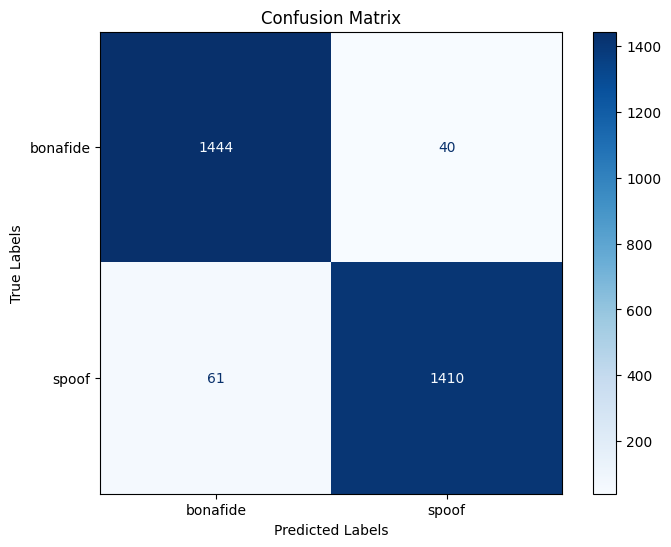

Model saved successfully!


In [ ]:
# Evaluating the Model
print("Evaluating the model...")
y_pred = (model.predict(X_test) > 0.5).astype(int)
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy on test set: {accuracy:.4f}")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=["bonafide", "spoof"]))

# Generate Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["bonafide", "spoof"])

# Plot Confusion Matrix
plt.figure(figsize=(8, 6))
disp.plot(cmap=plt.cm.Blues, ax=plt.gca())
plt.title("Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()


# Save the Model
model.save("/content/drive/My Drive/Final_Project/Audio_Detection/ENGR299/ASVspoof2021_DF_eval/deepfake_audio_model.h5")
print("Model saved successfully!")

# Plot Training and Validation Results
def plot_training(history):
    plt.figure(figsize=(12, 5))

    # Accuracy Plot
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Training Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()

    # Loss Plot
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    plt.tight_layout()